In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import datetime as dt
from geopy.distance import geodesic
import seaborn as sns

In [3]:
data = pd.read_csv(r'/media/abanoub/Storage1/My-Github/UK-Train-Rides/Dataset/railway_cleaned.csv')
# data = pd.read_csv(r"D:/UK-Train-Rides/Dataset/railway_cleaned.csv")
data.head()

,Transaction ID,Date of Purchase,Time of Purchase,Purchase Type,Payment Method,Railcard,Ticket Class,Ticket Type,Price,Departure Station,Arrival Destination,Date of Journey,Departure Time,Arrival Time,Actual Arrival Time,Journey Status,Reason for Delay,Refund Request,TimePeriod
0,da8a6ba8-b3dc-4677-b176,2023-12-08 12:41:11,12:41:11,Online,Contactless,Adult,Standard,Advance,43,London Paddington,Liverpool Lime Street,2024-01-01 11:00:00,11:00:00,13:30:00,13:30:00,On Time,No Reason,No,Dawn
1,b0cdd1b0-f214-4197-be53,2023-12-16 11:23:01,11:23:01,Station,Credit Card,Adult,Standard,Advance,23,London Kings Cross,York,2024-01-01 09:45:00,09:45:00,11:35:00,11:40:00,Delayed,Signal Failure,No,Morning
2,f3ba7a96-f713-40d9-9629,2023-12-19 19:51:27,19:51:27,Online,Credit Card,No Subscription,Standard,Advance,3,Liverpool Lime Street,Manchester Piccadilly,2024-01-02 18:15:00,18:15:00,18:45:00,18:45:00,On Time,No Reason,No,Noon
3,b2471f11-4fe7-4c87-8ab4,2023-12-20 23:00:36,23:00:36,Station,Credit Card,No Subscription,Standard,Advance,13,London Paddington,Reading,2024-01-01 21:30:00,21:30:00,22:30:00,22:30:00,On Time,No Reason,No,Noon
4,2be00b45-0762-485e-a7a3,2023-12-27 18:22:56,18:22:56,Online,Contactless,No Subscription,Standard,Advance,76,Liverpool Lime Street,London Euston,2024-01-01 16:45:00,16:45:00,19:00:00,19:00:00,On Time,No Reason,No,After Noon


In [4]:
time_cond = data['Actual Arrival Time'].astype(str) != '00:01:00'
data[time_cond]

,Transaction ID,Date of Purchase,Time of Purchase,Purchase Type,Payment Method,Railcard,Ticket Class,Ticket Type,Price,Departure Station,Arrival Destination,Date of Journey,Departure Time,Arrival Time,Actual Arrival Time,Journey Status,Reason for Delay,Refund Request,TimePeriod
0,da8a6ba8-b3dc-4677-b176,2023-12-08 12:41:11,12:41:11,Online,Contactless,Adult,Standard,Advance,43,London Paddington,Liverpool Lime Street,2024-01-01 11:00:00,11:00:00,13:30:00,13:30:00,On Time,No Reason,No,Dawn
1,b0cdd1b0-f214-4197-be53,2023-12-16 11:23:01,11:23:01,Station,Credit Card,Adult,Standard,Advance,23,London Kings Cross,York,2024-01-01 09:45:00,09:45:00,11:35:00,11:40:00,Delayed,Signal Failure,No,Morning
2,f3ba7a96-f713-40d9-9629,2023-12-19 19:51:27,19:51:27,Online,Credit Card,No Subscription,Standard,Advance,3,Liverpool Lime Street,Manchester Piccadilly,2024-01-02 18:15:00,18:15:00,18:45:00,18:45:00,On Time,No Reason,No,Noon
3,b2471f11-4fe7-4c87-8ab4,2023-12-20 23:00:36,23:00:36,Station,Credit Card,No Subscription,Standard,Advance,13,London Paddington,Reading,2024-01-01 21:30:00,21:30:00,22:30:00,22:30:00,On Time,No Reason,No,Noon
4,2be00b45-0762-485e-a7a3,2023-12-27 18:22:56,18:22:56,Online,Contactless,No Subscription,Standard,Advance,76,Liverpool Lime Street,London Euston,2024-01-01 16:45:00,16:45:00,19:00:00,19:00:00,On Time,No Reason,No,After Noon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31648,1304623d-b8b7-4999-8e9c,2024-04-30 18:42:58,18:42:58,Online,Credit Card,No Subscription,Standard,Off-Peak,4,Manchester Piccadilly,Liverpool Lime Street,2024-04-30 20:00:00,20:00:00,20:30:00,20:30:00,On Time,No Reason,No,NaN
31649,7da22246-f480-417c-bc2f,2024-04-30 18:46:10,18:46:10,Online,Contactless,No Subscription,Standard,Off-Peak,10,London Euston,Birmingham New Street,2024-04-30 20:15:00,20:15:00,21:35:00,21:35:00,On Time,No Reason,No,NaN
31650,add9debf-46c1-4c75-b52d,2024-04-30 18:56:41,18:56:41,Station,Credit Card,No Subscription,Standard,Off-Peak,4,Manchester Piccadilly,Liverpool Lime Street,2024-04-30 20:15:00,20:15:00,20:45:00,20:45:00,On Time,No Reason,No,NaN
31651,b92b047c-21fd-4859-966a,2024-04-30 19:51:47,19:51:47,Station,Credit Card,No Subscription,Standard,Off-Peak,10,London Euston,Birmingham New Street,2024-04-30 21:15:00,21:15:00,22:35:00,22:35:00,On Time,No Reason,No,NaN


#### Adding latitude and longitude for each station

In [5]:
data['Departure Station'].unique()
data['Arrival Destination'].unique()
departure = ['London Paddington', 'London Kings Cross', 'Liverpool Lime Street',
       'London Euston', 'York', 'Manchester Piccadilly',
       'Birmingham New Street', 'London St Pancras', 'Oxford', 'Reading',
       'Edinburgh Waverley', 'Bristol Temple Meads']
arrival = ['Liverpool Lime Street', 'York', 'Manchester Piccadilly',
       'Reading', 'London Euston', 'Oxford', 'Durham',
       'London St Pancras', 'Birmingham New Street', 'London Paddington',
       'Bristol Temple Meads', 'Tamworth', 'London Waterloo', 'Sheffield',
       'Wolverhampton', 'Leeds', 'Stafford', 'Doncaster', 'Swindon',
       'Nottingham', 'Peterborough', 'Edinburgh', 'Crewe',
       'London Kings Cross', 'Leicester', 'Nuneaton', 'Didcot',
       'Edinburgh Waverley', 'Coventry', 'Wakefield', 'Cardiff Central',
       'Warrington']
mixed = pd.Series(departure + arrival)
mixed.unique()

array(['London Paddington', 'London Kings Cross', 'Liverpool Lime Street',
       'London Euston', 'York', 'Manchester Piccadilly',
       'Birmingham New Street', 'London St Pancras', 'Oxford', 'Reading',
       'Edinburgh Waverley', 'Bristol Temple Meads', 'Durham', 'Tamworth',
       'London Waterloo', 'Sheffield', 'Wolverhampton', 'Leeds',
       'Stafford', 'Doncaster', 'Swindon', 'Nottingham', 'Peterborough',
       'Edinburgh', 'Crewe', 'Leicester', 'Nuneaton', 'Didcot',
       'Coventry', 'Wakefield', 'Cardiff Central', 'Warrington'],
      dtype=object)

In [6]:
# dictionary of pairs to save information of each station
stations = {
    'London Paddington' : {'Latitude' : 51.5163, 'Longitude' : 0.1766},
    'London Kings Cross' : {'Latitude' : 51.5316, 'Longitude' : 0.1236},
    'Liverpool Lime Street' : {'Latitude' : 53.4076, 'Longitude' : 2.9773},
    'London Euston' : {'Latitude' : 51.5280,'Longitude' : 0.1333},
    'York' : {'Latitude' : 53.9580, 'Longitude': 1.0932},
    'Manchester Piccadilly' : {'Latitude' : 53.4774, 'Longitude': 2.2312},
    'Birmingham New Street' : {'Latitude' : 52.4778, 'Longitude': 1.8990},
    'London St Pancras' : {'Latitude' : 51.5311, 'Longitude': 0.1259},
    'Oxford' : {'Latitude' : 51.7520, 'Longitude': 1.2577},
    'Reading' : {'Latitude' : 51.4584, 'Longitude': 0.9715},
    'Edinburgh Waverley' : {'Latitude' : 55.9524, 'Longitude': 3.1883},
    'Bristol Temple Meads' : {'Latitude' : 51.4497, 'Longitude': 2.5811},
    'Durham' : {'Latitude' : 54.7753, 'Longitude': 1.5849},
    'Tamworth' : {'Latitude' : 52.6336, 'Longitude': 1.6910},
    'London Waterloo' : {'Latitude' : 51.5049, 'Longitude': 0.1137},
    'Sheffield' : {'Latitude' : 53.3811, 'Longitude': 1.4701},
    'Wolverhampton' : {'Latitude' : 52.5868, 'Longitude': 2.1257},
    'Leeds' : {'Latitude' : 53.8008, 'Longitude': 1.5491},
    'Stafford' : {'Latitude' : 52.8068, 'Longitude' : 2.1220},
    'Doncaster' : {'Latitude' : 53.5228, 'Longitude' : 1.1323},
    'Swindon' : {'Latitude' : 51.5581, 'Longitude' : 1.7798},
    'Nottingham' : {'Latitude' : 52.9540, 'Longitude' : 1.1550},
    'Peterborough' : {'Latitude' : 52.5703, 'Longitude' : 0.2408},
    'Edinburgh' : {'Latitude' : 55.9533, 'Longitude' : 3.1883},
    'Crewe' : {'Latitude' : 53.1004, 'Longitude' : 2.4438},
    'Leicester' : {'Latitude' : 52.6369, 'Longitude' : 1.1398},
    'Nuneaton' : {'Latitude' : 52.5225, 'Longitude' : 1.4723},
    'Didcot' : {'Latitude' : 51.6080, 'Longitude' : 1.2448},
    'Coventry' : {'Latitude' : 52.4128, 'Longitude' : 1.5090},
    'Wakefield' : {'Latitude' : 53.6848, 'Longitude' : 1.5039},
    'Cardiff Central' : {'Latitude' : 51.5040, 'Longitude' : 3.1500},
    'Warrington' : {'Latitude' : 53.3920, 'Longitude' : 2.6023}
}

# map<string, map<string, int>>

In [7]:
data['Departure Latitude'], data['Departure Longitude'], data['Arrival Latitude'], data['Arrival Longitude'] = np.nan, np.nan, np.nan, np.nan

# For each station we need to update the lat and long
data['Departure Latitude'] = data['Departure Station'].map(lambda x : stations[x]['Latitude'])
data['Departure Longitude'] = data['Departure Station'].map(lambda x : stations[x]['Longitude'])
data['Arrival Latitude'] = data['Arrival Destination'].map(lambda x : stations[x]['Latitude'])
data['Arrival Longitude'] = data['Arrival Destination'].map(lambda x : stations[x]['Longitude'])

In [8]:
data.head()

,Transaction ID,Date of Purchase,Time of Purchase,Purchase Type,Payment Method,Railcard,Ticket Class,Ticket Type,Price,Departure Station,...,Arrival Time,Actual Arrival Time,Journey Status,Reason for Delay,Refund Request,TimePeriod,Departure Latitude,Departure Longitude,Arrival Latitude,Arrival Longitude
0,da8a6ba8-b3dc-4677-b176,2023-12-08 12:41:11,12:41:11,Online,Contactless,Adult,Standard,Advance,43,London Paddington,...,13:30:00,13:30:00,On Time,No Reason,No,Dawn,51.5163,0.1766,53.4076,2.9773
1,b0cdd1b0-f214-4197-be53,2023-12-16 11:23:01,11:23:01,Station,Credit Card,Adult,Standard,Advance,23,London Kings Cross,...,11:35:00,11:40:00,Delayed,Signal Failure,No,Morning,51.5316,0.1236,53.9580,1.0932
2,f3ba7a96-f713-40d9-9629,2023-12-19 19:51:27,19:51:27,Online,Credit Card,No Subscription,Standard,Advance,3,Liverpool Lime Street,...,18:45:00,18:45:00,On Time,No Reason,No,Noon,53.4076,2.9773,53.4774,2.2312
3,b2471f11-4fe7-4c87-8ab4,2023-12-20 23:00:36,23:00:36,Station,Credit Card,No Subscription,Standard,Advance,13,London Paddington,...,22:30:00,22:30:00,On Time,No Reason,No,Noon,51.5163,0.1766,51.4584,0.9715
4,2be00b45-0762-485e-a7a3,2023-12-27 18:22:56,18:22:56,Online,Contactless,No Subscription,Standard,Advance,76,Liverpool Lime Street,...,19:00:00,19:00:00,On Time,No Reason,No,After Noon,53.4076,2.9773,51.5280,0.1333


In [9]:
data['Date of Journey'] = pd.to_datetime(data['Date of Journey'],  format='%Y-%m-%d %H:%M:%S')
data['Date of Purchase'] = pd.to_datetime(data['Date of Purchase'],  format='%Y-%m-%d %H:%M:%S')

In [10]:
print(data.dtypes)

Transaction ID                 object
Date of Purchase       datetime64[ns]
Time of Purchase               object
Purchase Type                  object
Payment Method                 object
Railcard                       object
Ticket Class                   object
Ticket Type                    object
Price                           int64
Departure Station              object
Arrival Destination            object
Date of Journey        datetime64[ns]
Departure Time                 object
Arrival Time                   object
Actual Arrival Time            object
Journey Status                 object
Reason for Delay               object
Refund Request                 object
TimePeriod                     object
Departure Latitude            float64
Departure Longitude           float64
Arrival Latitude              float64
Arrival Longitude             float64
dtype: object


In [11]:
data.head()
data.columns

Index(['Transaction ID', 'Date of Purchase', 'Time of Purchase',
       'Purchase Type', 'Payment Method', 'Railcard', 'Ticket Class',
       'Ticket Type', 'Price', 'Departure Station', 'Arrival Destination',
       'Date of Journey', 'Departure Time', 'Arrival Time',
       'Actual Arrival Time', 'Journey Status', 'Reason for Delay',
       'Refund Request', 'TimePeriod', 'Departure Latitude',
       'Departure Longitude', 'Arrival Latitude', 'Arrival Longitude'],
      dtype='object')

### How many journeys

In [12]:
cond = data['Journey Status'] != 'Cancelled'
total_journey = data[['Date of Journey', 'Arrival Time', 'Departure Station', 'Arrival Destination']].drop_duplicates()

total_journey_not_cancelled = data.loc[cond, ['Date of Journey', 'Arrival Time', 'Departure Station', 'Arrival Destination']].drop_duplicates()

print(len(total_journey), len(total_journey_not_cancelled))

19871 19081


### Calculate a unique ID for each trip

In [13]:
total_journey = total_journey.reset_index(drop=True)

total_journey['Journey ID'] = total_journey.index + 1

data = data.merge(total_journey, on=['Date of Journey', 'Arrival Time', 'Departure Station', 'Arrival Destination'], how='left')
data.head()

,Transaction ID,Date of Purchase,Time of Purchase,Purchase Type,Payment Method,Railcard,Ticket Class,Ticket Type,Price,Departure Station,...,Actual Arrival Time,Journey Status,Reason for Delay,Refund Request,TimePeriod,Departure Latitude,Departure Longitude,Arrival Latitude,Arrival Longitude,Journey ID
0,da8a6ba8-b3dc-4677-b176,2023-12-08 12:41:11,12:41:11,Online,Contactless,Adult,Standard,Advance,43,London Paddington,...,13:30:00,On Time,No Reason,No,Dawn,51.5163,0.1766,53.4076,2.9773,1
1,b0cdd1b0-f214-4197-be53,2023-12-16 11:23:01,11:23:01,Station,Credit Card,Adult,Standard,Advance,23,London Kings Cross,...,11:40:00,Delayed,Signal Failure,No,Morning,51.5316,0.1236,53.9580,1.0932,2
2,f3ba7a96-f713-40d9-9629,2023-12-19 19:51:27,19:51:27,Online,Credit Card,No Subscription,Standard,Advance,3,Liverpool Lime Street,...,18:45:00,On Time,No Reason,No,Noon,53.4076,2.9773,53.4774,2.2312,3
3,b2471f11-4fe7-4c87-8ab4,2023-12-20 23:00:36,23:00:36,Station,Credit Card,No Subscription,Standard,Advance,13,London Paddington,...,22:30:00,On Time,No Reason,No,Noon,51.5163,0.1766,51.4584,0.9715,4
4,2be00b45-0762-485e-a7a3,2023-12-27 18:22:56,18:22:56,Online,Contactless,No Subscription,Standard,Advance,76,Liverpool Lime Street,...,19:00:00,On Time,No Reason,No,After Noon,53.4076,2.9773,51.5280,0.1333,5


In [14]:
len(data['Journey ID'].unique())


19871

In [15]:
data['Journey ID'].nunique()
data.groupby('Journey ID')['Transaction ID'].nunique()
ppl_per_trip = data.groupby('Journey ID')['Transaction ID'].nunique()


print("Max passengers in a trip:", ppl_per_trip.max())
print("Trips with only 1 passenger:", (ppl_per_trip == 1).sum())
print("Total trips counted:", len(ppl_per_trip))


Max passengers in a trip: 15
Trips with only 1 passenger: 13704
Total trips counted: 19871


In [16]:
data['Journey Status'].unique()

array(['On Time', 'Delayed', 'Cancelled'], dtype=object)

### Highest departure station rush

In [17]:
data.groupby('Departure Station')[['Departure Station', 'Transaction ID']].count().sort_values(by='Transaction ID', ascending=False)

,Departure Station,Transaction ID
Departure Station,,
Manchester Piccadilly,5650,5650
London Euston,4954,4954
Liverpool Lime Street,4561,4561
London Paddington,4500,4500
London Kings Cross,4229,4229
London St Pancras,3891,3891
Birmingham New Street,2136,2136
York,927,927
Reading,594,594


### Highest Arrival station rush based on journey id

In [18]:
data.groupby('Journey ID')[['Arrival Destination', 'Transaction ID']].count().sort_values(by='Transaction ID',
                                                                                               ascending=False)

,Arrival Destination,Transaction ID
Journey ID,,
18187,15,15
10663,14,14
2923,14,14
6261,13,13
1606,13,13
...,...,...
29,1,1
30,1,1
11,1,1


### top payment method ?

In [19]:
data.groupby('Payment Method')['Transaction ID'].count().sort_values(ascending=False)

Payment Method
Credit Card    19136
Contactless    10834
Debit Card      1683
Name: Transaction ID, dtype: int64

### most sold ticket type ?

In [20]:
data.groupby('Ticket Type')['Transaction ID'].count().sort_values(ascending=False)

Ticket Type
Advance     17561
Off-Peak     8752
Anytime      5340
Name: Transaction ID, dtype: int64

### delay reason distribution and solutions ?

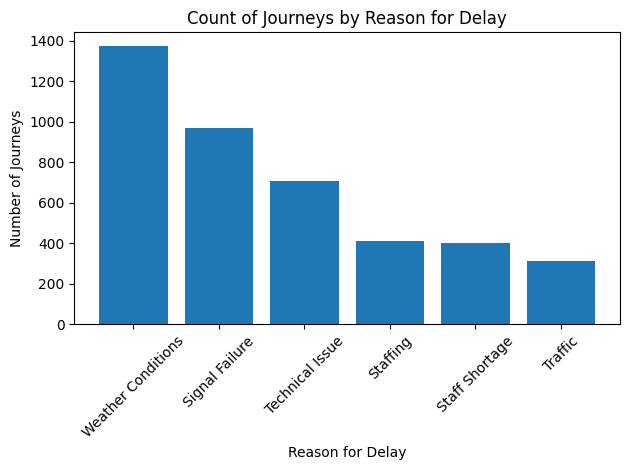

In [21]:
tmp = data[data['Reason for Delay'] != 'No Reason'].groupby('Reason for Delay')['Journey ID'].count().sort_values(ascending=False)
plt.bar(tmp.index, tmp.values)
plt.xticks(rotation=45)
plt.xlabel('Reason for Delay')
plt.ylabel('Number of Journeys')
plt.title('Count of Journeys by Reason for Delay')
plt.tight_layout()

### purchase type statistics ?

In [22]:
data.groupby('Purchase Type')['Transaction ID'].count().sort_values(ascending=False)

Purchase Type
Online     18521
Station    13132
Name: Transaction ID, dtype: int64

### Arrival time accuracy % ?

In [23]:
stat = data.groupby('Journey Status')['Journey ID'].count().sort_values(ascending=False)
accuracy = stat / data.shape[0] * 100
accuracy

Journey Status
On Time      86.819575
Delayed       7.241020
Cancelled     5.939405
Name: Journey ID, dtype: float64

In [24]:
data.head()

,Transaction ID,Date of Purchase,Time of Purchase,Purchase Type,Payment Method,Railcard,Ticket Class,Ticket Type,Price,Departure Station,...,Actual Arrival Time,Journey Status,Reason for Delay,Refund Request,TimePeriod,Departure Latitude,Departure Longitude,Arrival Latitude,Arrival Longitude,Journey ID
0,da8a6ba8-b3dc-4677-b176,2023-12-08 12:41:11,12:41:11,Online,Contactless,Adult,Standard,Advance,43,London Paddington,...,13:30:00,On Time,No Reason,No,Dawn,51.5163,0.1766,53.4076,2.9773,1
1,b0cdd1b0-f214-4197-be53,2023-12-16 11:23:01,11:23:01,Station,Credit Card,Adult,Standard,Advance,23,London Kings Cross,...,11:40:00,Delayed,Signal Failure,No,Morning,51.5316,0.1236,53.9580,1.0932,2
2,f3ba7a96-f713-40d9-9629,2023-12-19 19:51:27,19:51:27,Online,Credit Card,No Subscription,Standard,Advance,3,Liverpool Lime Street,...,18:45:00,On Time,No Reason,No,Noon,53.4076,2.9773,53.4774,2.2312,3
3,b2471f11-4fe7-4c87-8ab4,2023-12-20 23:00:36,23:00:36,Station,Credit Card,No Subscription,Standard,Advance,13,London Paddington,...,22:30:00,On Time,No Reason,No,Noon,51.5163,0.1766,51.4584,0.9715,4
4,2be00b45-0762-485e-a7a3,2023-12-27 18:22:56,18:22:56,Online,Contactless,No Subscription,Standard,Advance,76,Liverpool Lime Street,...,19:00:00,On Time,No Reason,No,After Noon,53.4076,2.9773,51.5280,0.1333,5


### travel time rush ? 

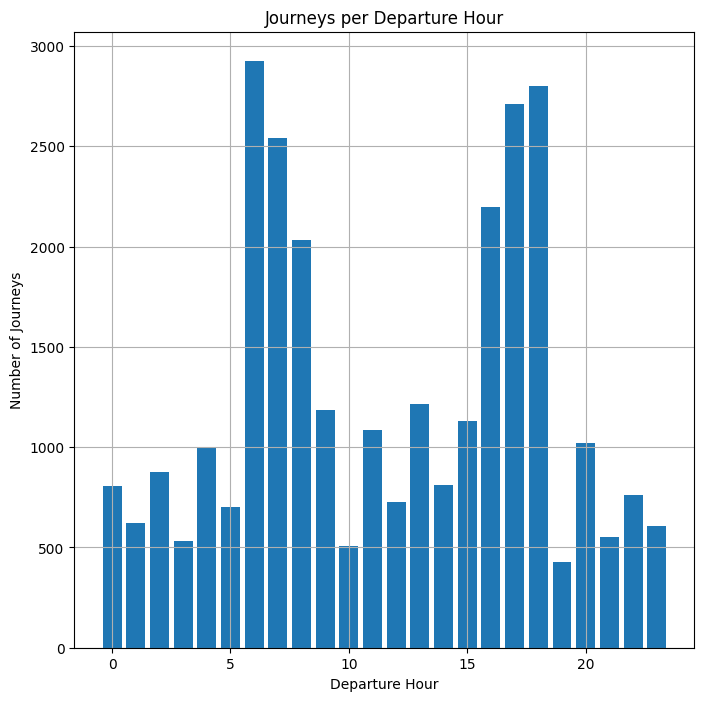

In [25]:
data['Departure Hour'] = data['Date of Journey'].dt.hour
data['Departure minute'] = data['Date of Journey'].dt.minute
cond = data['Journey Status'] != 'Cancelled'
counter = data[cond].groupby('Departure Hour')['Journey ID'].count().sort_values(ascending=False)

plt.figure(figsize=(8,8))
plt.bar(counter.index,counter.values)
plt.xlabel('Departure Hour')
plt.ylabel('Number of Journeys')
plt.title('Journeys per Departure Hour')
plt.grid(True)
plt.show()

### most canceled departure station ? -> NEEDS EDITS

In [26]:

cancelled_data = data[data['Journey Status'] == 'Cancelled']

cancelled_counts = cancelled_data['Departure Station'].value_counts()

most_cancelled_station = cancelled_counts.idxmax()

station_cancellations = cancelled_data[cancelled_data['Departure Station'] == most_cancelled_station]

reason_counts = station_cancellations['Reason for Delay'].value_counts()

most_common_reason = reason_counts.idxmax()
most_common_reason_count = reason_counts.max()

sorted_reasons = reason_counts.sort_values()

print(f"The most common reason for cancellations from {most_cancelled_station} is: {most_common_reason} with {most_common_reason_count} cancellations.")
print("\nOther reasons sorted in ascending order:")
print(sorted_reasons)


The most common reason for cancellations from London Paddington is: Weather Conditions with 82 cancellations.

Other reasons sorted in ascending order:
Reason for Delay
Traffic               46
Technical Issue       49
Staff Shortage        49
Staffing              57
Signal Failure        74
Weather Conditions    82
Name: count, dtype: int64


### best preforming hour in the day ?

In [27]:

data['Purchase Hour'] = data['Date of Purchase'].dt.hour


performance_hour = data.groupby('Purchase Hour')['Transaction ID'].count().sort_values(ascending=False)

print(performance_hour)

# why rush in 5 pm
# because of the discount from 16 to 18

Purchase Hour
17    2740
20    2239
9     2070
7     2046
8     2008
6     1910
14    1869
5     1566
15    1468
18    1425
10    1187
19    1160
3     1107
16    1056
1     1032
12    1025
0      925
4      924
13     754
11     743
23     726
2      642
21     573
22     458
Name: Transaction ID, dtype: int64


#### pseudo code

In [28]:
# Railcard	Whether the passenger is a National Railcard holder (Adult, Senior, or Disabled) or not (None). Railcard holders get 1/3 off their ticket purchases.

# price -> real price * discount
# if raildcard:
#     realprice -= realprice * 1/3
# else: price
#
#
# price = raalprice - realprice / 3
# realprice = price * (3 / 2)


#________________________________________________________________

# Ticket Type	When you bought or can use the ticket. Advance tickets are 1/2 off and must be purchased at least a day prior to departure.

# if ticke type == advance:
#     realprice / 2
# else if ticket type == off_peak:
#     realprice -=  realprice * 1 / 4
# else: realprice
#
#
# realprice = price * 2
#
# price = realprice - realprice / 4
#
# realprice = price * (4 / 3)



# combine both conditions together

# Off-Peak tickets are 1/4 off and must be used outside of peak hours (weekdays between 6-8am and 4-6pm). Anytime tickets are full price and can be bought and used at any time during the day.

### Calculate the price before any discount

In [29]:
railcard = data['Railcard'].unique()
ticket_type = data['Ticket Type'].unique()
def calc(type, price, sub):
    realprice = price
    # first check
    if type == 'Advance':
        realprice *= 2
    elif type == 'Off-Peak':
        realprice *= (4 / 3)

    # second check
    if sub != 'No Subscription':
        realprice *= (3 / 2)
    return realprice

data['Old Price'] = data[['Ticket Type', 'Price', 'Railcard']].apply(lambda x : calc(x['Ticket Type'], x['Price'], x['Railcard']), axis=1)

data[['Price', 'Old Price', 'Ticket Type', 'Railcard']]
#ticket type , price, railcard,

,Price,Old Price,Ticket Type,Railcard
0,43,129.000000,Advance,Adult
1,23,69.000000,Advance,Adult
2,3,6.000000,Advance,No Subscription
3,13,26.000000,Advance,No Subscription
4,76,152.000000,Advance,No Subscription
...,...,...,...,...
31648,4,5.333333,Off-Peak,No Subscription
31649,10,13.333333,Off-Peak,No Subscription
31650,4,5.333333,Off-Peak,No Subscription
31651,10,13.333333,Off-Peak,No Subscription


### How much revenue lost due to journey status and refund 	-> mohamed

In [30]:
data['refund'] = data.apply(lambda row: row['Price'] if str(row['Refund Request']).lower() == "yes" else 0, axis=1)

gross_revenue = data['Price'].sum()
total_refunds = data['refund'].sum()
net_revenue   = gross_revenue - total_refunds
loss_ratio    = (total_refunds / gross_revenue) * 100

print( gross_revenue)
print( total_refunds)
print( net_revenue)
print("loss_ratio    : %.2f%%" % loss_ratio)


summary = data.groupby('Journey Status').agg(
    total_fare=('Price', 'sum'),
    total_refund=('refund', 'sum')
)
summary['loss_ratio'] = (summary['total_refund'] / summary['total_fare']) * 100

print(summary)

741921
38702
703219
loss_ratio    : 5.22%
                total_fare  total_refund  loss_ratio
Journey Status                                      
Cancelled            45456         12537   27.580517
Delayed             126814         26165   20.632580
On Time             569651             0    0.000000


### discount statistics ? -> Mohamed

In [31]:
data['Discount'] = data['Old Price'] - data['Price']
total_discount = data['Discount'].sum()

avg_discount = data['Discount'].mean()

gross_revenue = data['Price'].sum()
discount_ratio = (total_discount / gross_revenue) * 100

print( total_discount )
print( avg_discount )
print( discount_ratio )


510592.1666666666
16.13092492549416
68.8202876946018


### compare between the weekend journeys and not weekend journneys ? -> Abanoub

Text(0.5, 1.0, 'Weekend Vs Normal Days')

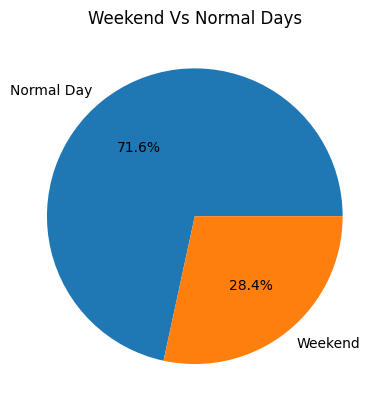

In [32]:
# getting day name
data['Journey Day'] = data['Date of Journey'].dt.day_name()

weekends = ['Saturday', 'Sunday']
def check(day):
    if day in weekends:
        return 'Weekend'
    return 'Normal Day'
data['Journey Day'] = data['Journey Day'].apply(lambda x : check(x))
tmp = data['Journey Day'].value_counts()

plt.pie(tmp, labels=tmp.index, autopct='%1.1f%%')
plt.title('Weekend Vs Normal Days')

In [33]:
normal_count = tmp.values[0]

weekend_count = tmp.values[1]

weekend_ratio = weekend_count / 2
normal_ratio = normal_count / 5
print(f'weekend_ratio -> {weekend_ratio} \n normal ratio -> {normal_ratio}')

# as we see weekends are the best

weekend_ratio -> 4493.5 
 normal ratio -> 4533.2


### How many passengers ride the trains per month ?

<Axes: xlabel='Month'>

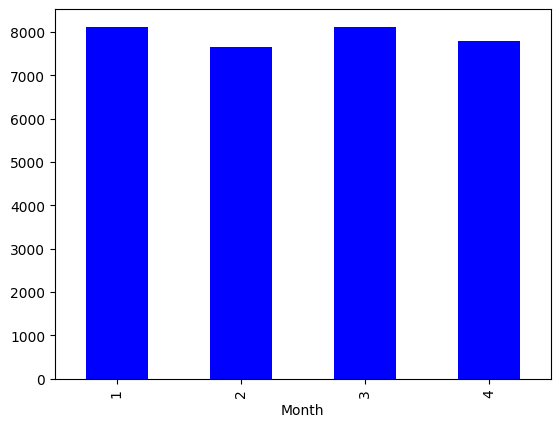

In [34]:
data['Month']=data['Date of Journey'].dt.month
data.groupby('Month')['Transaction ID'].count().plot(kind='bar', color='Blue')

### Calc the distance between departure station and arrival

In [35]:
data["km"] = data.apply(
    lambda x: geodesic(
        (x['Departure Latitude'], x['Departure Longitude']),
        (x['Arrival Latitude'], x['Arrival Longitude'])
    ).km,
    axis=1
)

In [36]:
data["km"].unique()


array([283.73298199, 277.83207598,  50.18213755,  55.58777975,
       284.73982297,  81.73090504, 278.06865854,  96.42494992,
       160.99330611, 113.45699841, 160.83894196, 258.99827271,
        97.66674761,  22.35161493, 259.49401791,   4.54726172,
        51.71247059, 180.57491836, 104.17625366,  39.6007426 ,
        48.50648505,  57.20407721,  79.31145293,  92.52669363,
        57.71386538, 164.57641391, 284.88847248, 259.49852031,
        49.36299338, 259.51855155, 141.31073766,  29.40096457,
       130.10736701, 173.29988209,  25.2324143 ,  38.21266609,
       126.3353264 , 531.8343134 ,  92.22423608, 284.82369215,
       100.30633507, 395.87319816, 159.4912954 , 259.479387  ,
        27.48653082,  34.71414062, 256.20993449, 259.41355031,
       161.07589288,  19.59041206,  40.69592777, 138.73861771,
        39.98364735,  26.43162447])

In [37]:
len(data["km"].unique())

54

### Delay duration

In [38]:
from datetime import datetime

def time(departure, arrival):
    fmt = "%H:%M:%S"
    dep = datetime.strptime(departure, fmt)
    arr = datetime.strptime(arrival, fmt)
    diff = arr - dep
    hours = diff.total_seconds() / 3600
    return round(hours, 2)

cond = ((data['Journey Status'] != 'Cancelled'))

data.loc[cond, 'Delay'] = data.loc[cond, ['Arrival Time', 'Actual Arrival Time']].apply(
    lambda x: time(x['Arrival Time'], x['Actual Arrival Time']),
    axis=1
)

grouped_delay = data.groupby('Journey ID')['Delay'].mean().round(2)

total_delay = grouped_delay.sum()

print(grouped_delay.head())
print("\nTotal delay (hours):", total_delay)


Journey ID
1    0.00
2    0.08
3    0.00
4    0.00
5    0.00
Name: Delay, dtype: float64

Total delay (hours): 667.79


### Efficiency of the ticket
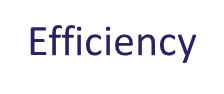

In [39]:
data['Price'].mean()

np.float64(23.439200075822196)

In [40]:
data['Ticket Class'].unique()

array(['Standard', 'First Class'], dtype=object)

In [41]:
data.columns

Index(['Transaction ID', 'Date of Purchase', 'Time of Purchase',
       'Purchase Type', 'Payment Method', 'Railcard', 'Ticket Class',
       'Ticket Type', 'Price', 'Departure Station', 'Arrival Destination',
       'Date of Journey', 'Departure Time', 'Arrival Time',
       'Actual Arrival Time', 'Journey Status', 'Reason for Delay',
       'Refund Request', 'TimePeriod', 'Departure Latitude',
       'Departure Longitude', 'Arrival Latitude', 'Arrival Longitude',
       'Journey ID', 'Departure Hour', 'Departure minute', 'Purchase Hour',
       'Old Price', 'refund', 'Discount', 'Journey Day', 'Month', 'km',
       'Delay'],
      dtype='object')

In [42]:
first_class = data[data['Ticket Class'] == 'First Class']
val = first_class['Old Price'] / first_class['km']
print(f'first class -> {val.mean()}')

standard = data[data['Ticket Class'] == 'Standard']
val2 = standard['Old Price'] / standard['km']
print(f'standard -> {val2.mean()}')

first class -> 0.6166695042572328
standard -> 0.2401713327941003


### Revenue by ticket class and type ?

In [43]:
data.groupby('Ticket Class')['Price'].sum()

Ticket Class
First Class    149399
Standard       592522
Name: Price, dtype: int64

In [44]:
data.groupby('Ticket Type')['Price'].sum()

Ticket Type
Advance     309274
Anytime     209309
Off-Peak    223338
Name: Price, dtype: int64

### best preforming day in every week ? depending on tickets sold

In [45]:
data['Purchase Day'] = data['Date of Purchase'].dt.day_name()


### how many delayed hours had the trains delayed this week ?

In [46]:
# 1️⃣ نسخ الأعمدة بدل تعديل الأصل
arrival = pd.to_datetime(data["Arrival Time"], format="%H:%M:%S", errors="coerce")
actual  = pd.to_datetime(data["Actual Arrival Time"], format="%H:%M:%S", errors="coerce")
journey = pd.to_datetime(data["Date of Journey"], errors="coerce")

# 2️⃣ تعديل اليوم في النسخ فقط
mask = actual < arrival
actual_corrected = actual.copy()
actual_corrected[mask] = actual_corrected[mask] + pd.Timedelta(days=1)

# 3️⃣ حساب التأخير (بدون تعديل أي عمود في data)
delay_hours = (actual_corrected - arrival).dt.total_seconds() / 3600

# 4️⃣ حساب الأسبوع الأخير
today = journey.max()
firstday = today - dt.timedelta(days=6)
lastday  = firstday + dt.timedelta(days=6)

week_mask = (journey >= firstday) & (journey <= lastday)

delayed_hours_sum = delay_hours[week_mask].sum()

print(int(delayed_hours_sum))


1180


In [47]:
# 1️⃣ إضافة عمود الأسبوع واسم اليوم (من journey النسخة المؤقتة)
week_numbers = journey.dt.isocalendar().week
journey_day_names = journey.dt.day_name()

# 2️⃣ تجميع حسب الأسبوع واليوم وحساب متوسط التأخير من النسخ المؤقتة
weekavgdelay = (
    pd.DataFrame({
        "Week": week_numbers,
        "Journey Day": journey_day_names,
        "Delay Hours": delay_hours
    })
    .groupby(["Week", "Journey Day"], as_index=False)["Delay Hours"]
    .mean()
)

# 3️⃣ اختيار اليوم الأقل تأخير لكل أسبوع
weekbestday = weekavgdelay.loc[weekavgdelay.groupby("Week")["Delay Hours"].idxmin()]

# 4️⃣ عدد مرات ظهور أفضل يوم عبر كل الأسابيع
finalbestday = weekbestday["Journey Day"].value_counts()

print(finalbestday)


Journey Day
Wednesday    5
Thursday     4
Monday       3
Friday       3
Saturday     2
Tuesday      1
Name: count, dtype: int64


### Mahmoooooood -> EDIT

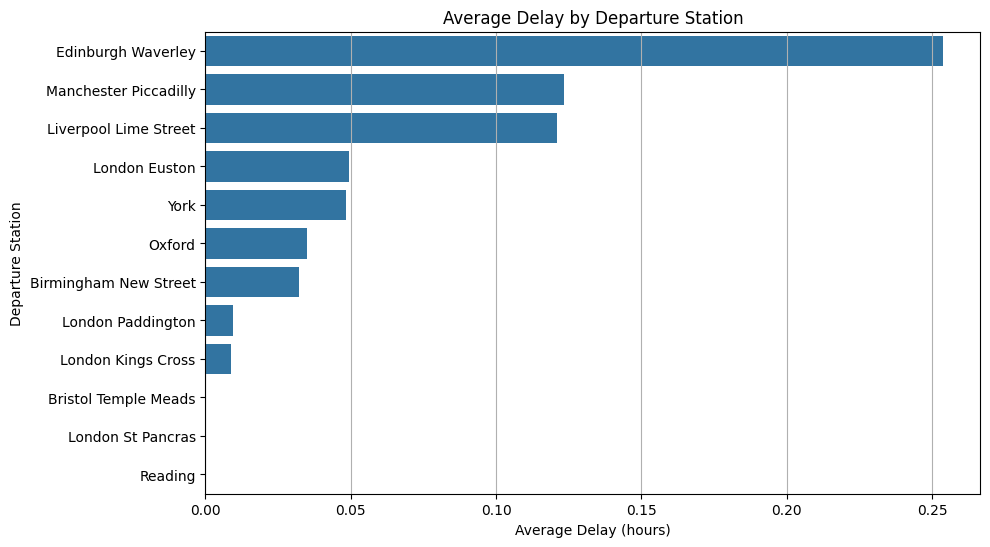

🔝 Top stations by average delay:
Departure Station
Edinburgh Waverley       0.253922
Manchester Piccadilly    0.123477
Liverpool Lime Street    0.120913
London Euston            0.049383
York                     0.048448
Oxford                   0.034928
Birmingham New Street    0.032201
London Paddington        0.009464
London Kings Cross       0.008766
Bristol Temple Meads     0.000000
Name: Delay, dtype: float64


In [48]:
station_delay = data.groupby("Departure Station")["Delay"].mean().sort_values(ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(x=station_delay.values, y=station_delay.index)
plt.title("Average Delay by Departure Station")
plt.xlabel("Average Delay (hours)")
plt.ylabel("Departure Station")
plt.grid(axis='x')
plt.show()

print("🔝 Top stations by average delay:")
print(station_delay.head(10))
# محطات الشمال (Edinburgh, Manchester, Liverpool) بتسجل أعلى نسب تأخير.

# محطات لندن (Paddington, Kings Cross) تقريبًا في قمة الانضباط الزمني.

# المحطات الجنوبية زي Bristol تكاد تكون بدون تأخير

### Relationship between Distance and Delay

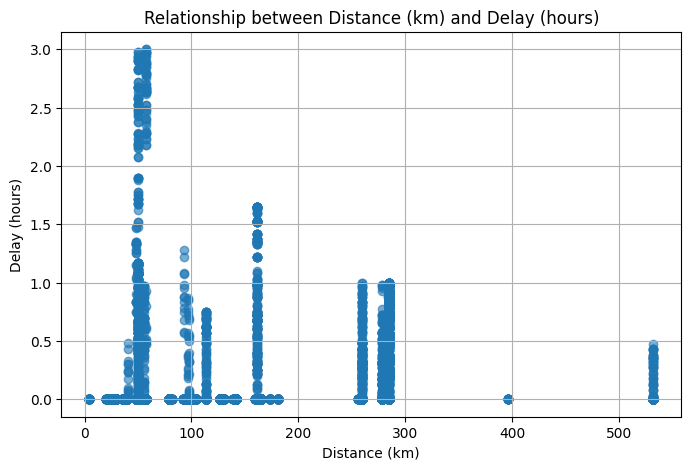

📈 Correlation between Distance and Delay: 0.06


In [49]:
plt.figure(figsize=(8,5))
plt.scatter(data["km"], data["Delay"], alpha=0.6)
plt.title("Relationship between Distance (km) and Delay (hours)")
plt.xlabel("Distance (km)")
plt.ylabel("Delay (hours)")
plt.grid(True)
plt.show()

correlation_km_delay = data["km"].corr(data["Delay"])
print(f"📈 Correlation between Distance and Delay: {correlation_km_delay:.2f}")
#Most delays are concentrated during evening rush hours and at high-traffic stations.
#Operational reasons and congestion are the leading causes, not route length or ticket type.”


### What is the effect of price on sales volume?
### No effect

In [50]:
monthly = data.groupby("Month").agg({"Price":"mean","Transaction ID":"count"}).rename(columns={"Transaction ID":"Sales"})
monthly["pct_price"] = monthly["Price"].pct_change()
monthly["pct_sales"] = monthly["Sales"].pct_change()
monthly["elasticity"] = monthly["pct_sales"] / monthly["pct_price"]
monthly


,Price,Sales,pct_price,pct_sales,elasticity
Month,,,,,
1,24.610775,8111,NaN,NaN,NaN
2,20.849555,7644,-0.152828,-0.057576,0.376738
3,24.041764,8117,0.153107,0.061879,0.404153
4,24.133402,7781,0.003812,-0.041395,-10.860154


### Which stations have the highest refund request rate?

In [51]:
station_analysis = (
    data.groupby("Departure Station").agg({
        "Journey ID": "nunique",
        "refund": "sum",
        "Price": "sum",
        "Delay": "mean"
    })
    .rename(columns={
        "Journey ID": "Journeys",
        "refund": "TotalRefunds",
        "Price": "TotalRevenue",
        "Delay": "AvgDelay"
    })
)

refund_ratio = (
    data[data["refund"] > 0]
    .groupby("Departure Station")["Journey ID"]
    .nunique()
    / data.groupby("Departure Station")["Journey ID"].nunique()
)

station_analysis["RefundRate"] = refund_ratio

station_analysis = station_analysis.fillna(0)

station_analysis = station_analysis.sort_values(by="RefundRate", ascending=False)

station_analysis.reset_index().head(15)


,Departure Station,Journeys,TotalRefunds,TotalRevenue,AvgDelay,RefundRate
0,Edinburgh Waverley,43,2093,2093,0.253922,1.000000
1,Oxford,129,332,2859,0.034928,0.147287
2,Birmingham New Street,1394,2224,38116,0.032201,0.090387
3,Liverpool Lime Street,2997,14587,135274,0.120913,0.085085
4,Manchester Piccadilly,3521,9463,75314,0.123477,0.050554
5,London Paddington,2643,1792,83842,0.009464,0.037457
6,Reading,459,179,10127,0.000000,0.037037
7,London Euston,3059,2778,112045,0.049383,0.033671
8,London Kings Cross,2625,3880,199650,0.008766,0.031619
9,London St Pancras,2332,1016,62957,0.000000,0.029160


In [52]:
data.shape[0] - data[time_cond].shape[0]

1880

In [53]:
# *************************************
# data['Arrival Time'] = pd.to_datetime(data['Arrival Time'], format='%H:%M:%S', errors='coerce')
# data['Actual Arrival Time'] = pd.to_datetime(data['Actual Arrival Time'], format='%H:%M:%S', errors='coerce')
# data['Delay Duration (minutes)'] = (data[data['Journey Status'] != 'Cancelled'] - data[data['Journey Status'] != 'Cancelled']).dt.total_seconds() / 60
# data.groupby('Journey ID')['Delay Duration (minutes)'].sum()
print(data.dtypes)

Transaction ID                 object
Date of Purchase       datetime64[ns]
Time of Purchase               object
Purchase Type                  object
Payment Method                 object
Railcard                       object
Ticket Class                   object
Ticket Type                    object
Price                           int64
Departure Station              object
Arrival Destination            object
Date of Journey        datetime64[ns]
Departure Time                 object
Arrival Time                   object
Actual Arrival Time            object
Journey Status                 object
Reason for Delay               object
Refund Request                 object
TimePeriod                     object
Departure Latitude            float64
Departure Longitude           float64
Arrival Latitude              float64
Arrival Longitude             float64
Journey ID                      int64
Departure Hour                  int32
Departure minute                int32
Purchase Hou

    ### Measures & Calculations

In [54]:
hour_col = 'Departure Hour'
minute_col = 'Departure minute'

# 2️⃣ إنشاء وقت فعلي من الساعات والدقايق
copy = pd.to_datetime(
    data[hour_col].astype(str) + ':' + data[minute_col].astype(str).str.zfill(2),
    format='%H:%M',
    errors='coerce'
).dt.time   # ← خُد الوقت فقط من غير تاريخ

# 3️⃣ دالة لتحديد الفترة الزمنية
def get_time_period(time):
    hour = time.hour
    if 4 <= hour < 6:
        return 'Dawn'
    elif 6 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Noon'
    elif 17 <= hour < 21:
        return 'After Noon'
    elif 21 <= hour < 24:
        return 'Night'
    elif 0 <= hour < 4:
        return 'Late Night'
    else:
        return 'Unknown'

# 4️⃣ تطبيق الدالة
data['TimePeriod'] = copy.apply(get_time_period)


In [55]:
data.head()

,Transaction ID,Date of Purchase,Time of Purchase,Purchase Type,Payment Method,Railcard,Ticket Class,Ticket Type,Price,Departure Station,...,Departure minute,Purchase Hour,Old Price,refund,Discount,Journey Day,Month,km,Delay,Purchase Day
0,da8a6ba8-b3dc-4677-b176,2023-12-08 12:41:11,12:41:11,Online,Contactless,Adult,Standard,Advance,43,London Paddington,...,0,12,129.0,0,86.0,Normal Day,1,283.732982,0.00,Friday
1,b0cdd1b0-f214-4197-be53,2023-12-16 11:23:01,11:23:01,Station,Credit Card,Adult,Standard,Advance,23,London Kings Cross,...,45,11,69.0,0,46.0,Normal Day,1,277.832076,0.08,Saturday
2,f3ba7a96-f713-40d9-9629,2023-12-19 19:51:27,19:51:27,Online,Credit Card,No Subscription,Standard,Advance,3,Liverpool Lime Street,...,15,19,6.0,0,3.0,Normal Day,1,50.182138,0.00,Tuesday
3,b2471f11-4fe7-4c87-8ab4,2023-12-20 23:00:36,23:00:36,Station,Credit Card,No Subscription,Standard,Advance,13,London Paddington,...,30,23,26.0,0,13.0,Normal Day,1,55.587780,0.00,Wednesday
4,2be00b45-0762-485e-a7a3,2023-12-27 18:22:56,18:22:56,Online,Contactless,No Subscription,Standard,Advance,76,Liverpool Lime Street,...,45,18,152.0,0,76.0,Normal Day,1,284.739823,0.00,Wednesday


### For each reson for delay how many people

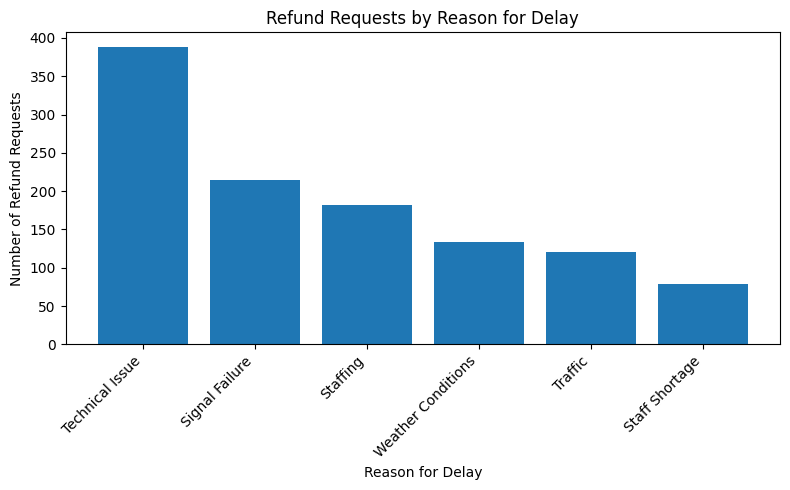

In [56]:
refund = data['Refund Request'] == 'Yes'
tmp = data[refund]
ans1 = tmp.groupby('Reason for Delay')['Transaction ID'].count().sort_values(ascending=False)

plt.figure(figsize=(8,5))
plt.bar(ans1.index, ans1.values)
plt.title('Refund Requests by Reason for Delay')
plt.xlabel('Reason for Delay')
plt.ylabel('Number of Refund Requests')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### How many people requested refund without reason for delay?

In [57]:
print(data[(data['Reason for Delay'] == 'No Reason' )& (data['Refund Request'] == 'Yes')].size)

0


#### repeated

In [58]:
# # weekend -> [Saturday, Sunday]
# li = ['Saturday', 'Sunday']
# data['Day Name'] = data['Date of Journey'].dt.day_name()
# data['day type'] = data['Day Name'].apply(lambda x : 'weekend' if x in li else 'normal')
# data['day type'].unique()

In [59]:
data['day number'] = data['Date of Journey'].dt.day

In [60]:
data.to_csv(r'/media/abanoub/Storage1/My-Github/UK-Train-Rides/Dataset/railway_after_analysis.csv', index=False)
# data.to_csv(r'D:/UK-Train-Rides/Dataset/railway_after_analysis.csv', index=False)
